# HNN Ideal Mass-Spring Experiment

In [4]:
%load_ext autoreload
%autoreload 2

import argparse
import matplotlib.pyplot as plt
import numpy as np
import torch

import model_api
from model_api import load_model, sample_batch
from model_api.train import train
from model_api.data import get_dataset, get_field, get_trajectory

print(model_api.__file__)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
C:\Users\RDEL1BCC\Documents\progs\python\deep_learning\hnn\src\model_api\__init__.py


In [5]:
field = get_field()
dataset = get_dataset()
dataset

{'x': array([[ 0.08047354, -0.06354789],
        [-0.00924063, -0.10803434],
        [ 0.05293825, -0.10030653],
        ...,
        [-0.27739328, -0.86929107],
        [-0.45702229, -0.81420538],
        [-0.64736244, -0.69679708]], shape=(750, 2)),
 'test_x': array([[-0.05078723,  0.55477802],
        [ 0.04318766,  0.5411715 ],
        [ 0.15772386,  0.36006439],
        ...,
        [-0.48493392,  0.04013209],
        [-0.08368154,  0.01431885],
        [-0.2929535 ,  0.09531511]], shape=(750, 2)),
 'dx': array([[-0.23526489, -0.13996706],
        [-0.25900051, -0.08865261],
        [-0.27168761, -0.03355748],
        ...,
        [-1.85678948,  0.66018416],
        [-1.68157253,  1.0275332 ],
        [-1.4346302 ,  1.35105354]], shape=(750, 2)),
 'test_dx': array([[ 1.00840684,  0.1340651 ],
        [ 1.0144411 , -0.07594517],
        [ 0.97720505, -0.2827157 ],
        ...,
        [-0.0133713 ,  0.52193032],
        [ 0.09413114,  0.51354588],
        [ 0.19761749,  0.48325656]

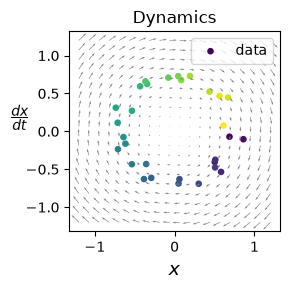

In [7]:

# plot config
fig = plt.figure(figsize=(3, 3), facecolor='white')

x, y, dx, dy, t = get_trajectory(radius=0.7, y0=np.array([1,0]))
plt.scatter(x,y,c=t,s=14, label='data')
plt.quiver(field['x'][:,0], field['x'][:,1], field['dx'][:,0], field['dx'][:,1],
           cmap='gray_r', color=(.5,.5,.5))
plt.xlabel("$x$", fontsize=14)
plt.ylabel("$\\frac{dx}{dt}$", rotation=0, fontsize=14)
plt.title("Dynamics")
plt.legend(loc='upper right')

plt.tight_layout() ; plt.show()


In [ ]:

DEVICE = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {DEVICE} device")

Using cuda device


In [9]:
def get_vector_field(model, **kwargs):
    field = data.get_field(**kwargs)
    np_mesh_x = field['x']
    
    # run model
    mesh_x = torch.tensor( np_mesh_x, requires_grad=True, dtype=torch.float32)
    mesh_dx = model.time_derivative(mesh_x)
    return mesh_dx.data.numpy()

In [10]:
from scipy.integrate import solve_ivp

def integrate_model(model, t_span, y0, **kwargs):
    
    def fun(t, np_x):
        x = torch.tensor( np_x, requires_grad=True, dtype=torch.float32).view(1,2).to(DEVICE)
        dx = model(x).detach().cpu().numpy().reshape(-1)
        return dx

    return solve_ivp(fun=fun, t_span=t_span, y0=y0, **kwargs)

In [11]:
def make_args(baseline: bool = False, total_steps: int = 2000) -> argparse.Namespace:
    return argparse.Namespace(
        input_dim=2,
        hidden_dim=200,
        learn_rate=1e-3,
        nonlinearity="tanh",
        total_steps=total_steps,
        print_every=500,
        name="spring",
        baseline=baseline,
        use_rk4=False,
        verbose=False,
        field_type="solenoidal",
        seed=0,
        save_dir="",
    )

Final train loss 3.4819e-02 +/- 1.9244e-03
Final test loss 4.0256e-02 +/- 1.9662e-03
Final train loss 3.5212e-02 +/- 1.9518e-03
Final test loss 4.0498e-02 +/- 1.9767e-03


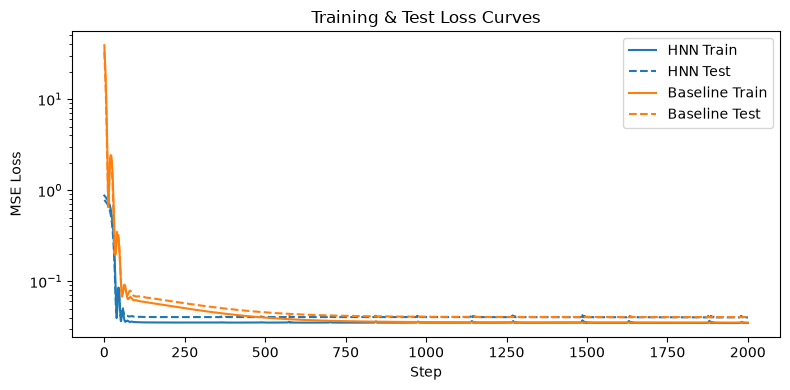

In [12]:
hnn_model, hnn_stats = train(make_args(baseline=False))
base_model, base_stats = train(make_args(baseline=True))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hnn_stats["train_loss"], label="HNN Train", color="tab:blue")
ax.plot(hnn_stats["test_loss"], "--", label="HNN Test", color="tab:blue")
ax.plot(base_stats["train_loss"], label="Baseline Train", color="tab:orange")
ax.plot(base_stats["test_loss"], "--", label="Baseline Test", color="tab:orange")
ax.set_yscale("log")
ax.set_xlabel("Step")
ax.set_ylabel("MSE Loss")
ax.set_title("Training & Test Loss Curves")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
base_field = get_vector_field(model, gridsize=10)
field = get_field()
np_mesh_x = field['x']
mesh_x = torch.tensor(np_mesh_x, requires_grad=True, dtype=torch.float32).to(DEVICE)
base_field = mesh_dx = model(mesh_x).detach().cpu()


In [69]:
# integrate along those fields starting from point (1,0)
t_span = [0,30]
y0 = np.asarray([1., 0])
kwargs = {'t_eval': np.linspace(t_span[0], t_span[1], 2000), 'rtol': 1e-12}
base_ivp = integrate_model(model, t_span, y0, **kwargs)
#hnn_ivp = integrate_model(hnn_model, t_span, y0, **kwargs)

In [70]:
base_ivp

  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  1.501e-02 ...  2.998e+01  3.000e+01]
        y: [[ 1.000e+00  9.990e-01 ...  6.155e-01  6.309e-01]
            [ 0.000e+00 -2.690e-02 ...  5.579e-01  5.401e-01]]
      sol: None
 t_events: None
 y_events: None
     nfev: 2312
     njev: 0
      nlu: 0

Text(0.5, 1.0, 'Baseline NN')

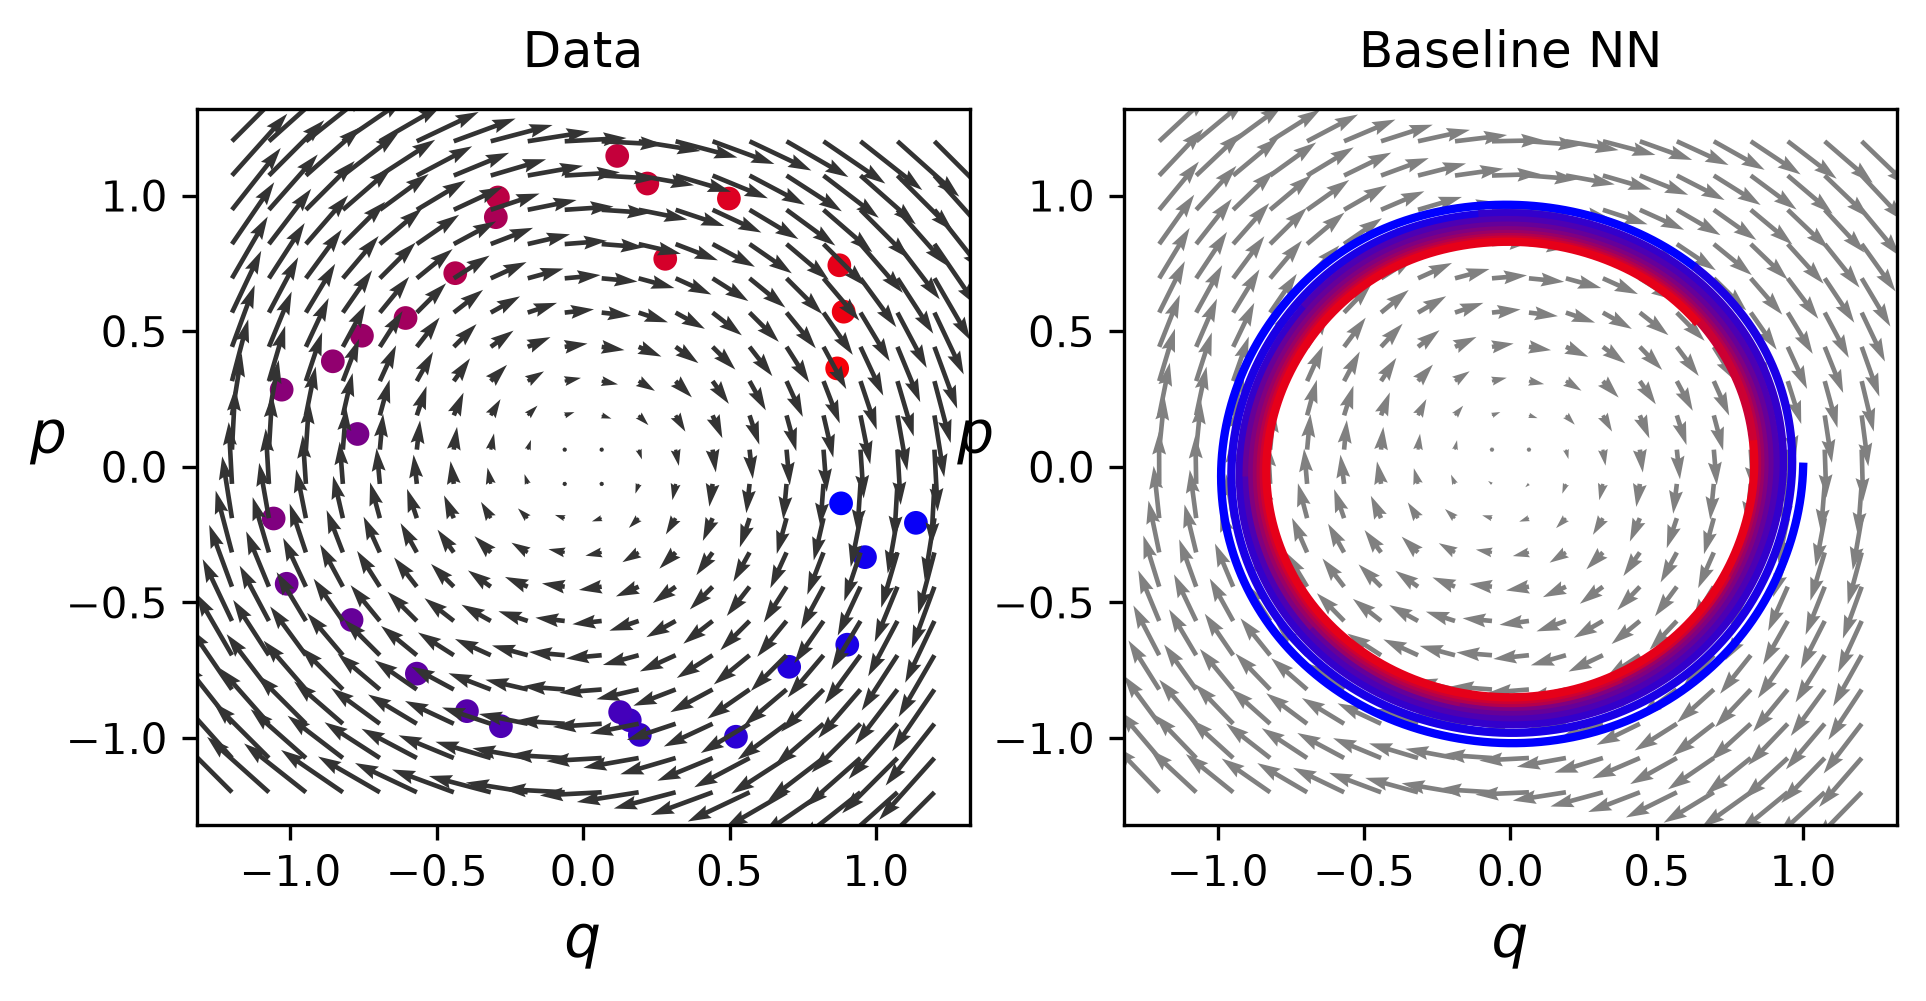

In [77]:

DPI = 300
FORMAT = 'pdf'
LINE_SEGMENTS = 10
ARROW_SCALE = 30
ARROW_WIDTH = 6e-3
LINE_WIDTH = 2
RK4 = ''


fig = plt.figure(figsize=(11.3, 3.1), facecolor='white', dpi=300)

fig.add_subplot(1, 3, 1, frameon=True)
x, y, dx, dy, t = data.get_trajectory(radius=1, y0=np.array([1,0]))
N = len(x)
point_colors = [(i/N, 0, 1-i/N) for i in range(N)]
plt.scatter(x,y, s=22, label='data', c=point_colors)

plt.quiver(field['x'][:,0], field['x'][:,1], field['dx'][:,0], field['dx'][:,1],
        cmap='gray_r', scale=ARROW_SCALE, width=ARROW_WIDTH, color=(.2,.2,.2))  
plt.xlabel("$q$", fontsize=14)
plt.ylabel("$p$", rotation=0, fontsize=14)
plt.title("Data", pad=10)

fig.add_subplot(1, 3, 2, frameon=True)
plt.quiver(field['x'][:,0], field['x'][:,1], base_field[:,0], base_field[:,1],
        cmap='gray_r', scale=ARROW_SCALE, width=ARROW_WIDTH, color=(.5,.5,.5))

for i, l in enumerate(np.split(base_ivp['y'].T, LINE_SEGMENTS)):
    color = (float(i)/LINE_SEGMENTS, 0, 1-float(i)/LINE_SEGMENTS)
    plt.plot(l[:,0],l[:,1],color=color, linewidth=LINE_WIDTH)
    
plt.xlabel("$q$", fontsize=14)
plt.ylabel("$p$", rotation=0, fontsize=14)
plt.title("Baseline NN", pad=10)



In [83]:
untrained_model = BaselineMLP().to(DEVICE)

field = data.get_field()
np_mesh_x = field['x']
mesh_x = torch.tensor(np_mesh_x, requires_grad=True, dtype=torch.float32).to(DEVICE)
base_field = mesh_dx = untrained_model(mesh_x).detach().cpu()

t_span = [0,30]
y0 = np.asarray([1., 0])
kwargs = {'t_eval': np.linspace(t_span[0], t_span[1], 2000), 'rtol': 1e-12}
base_ivp = integrate_model(untrained_model, t_span, y0, **kwargs)


Text(0.5, 1.0, 'Baseline NN')

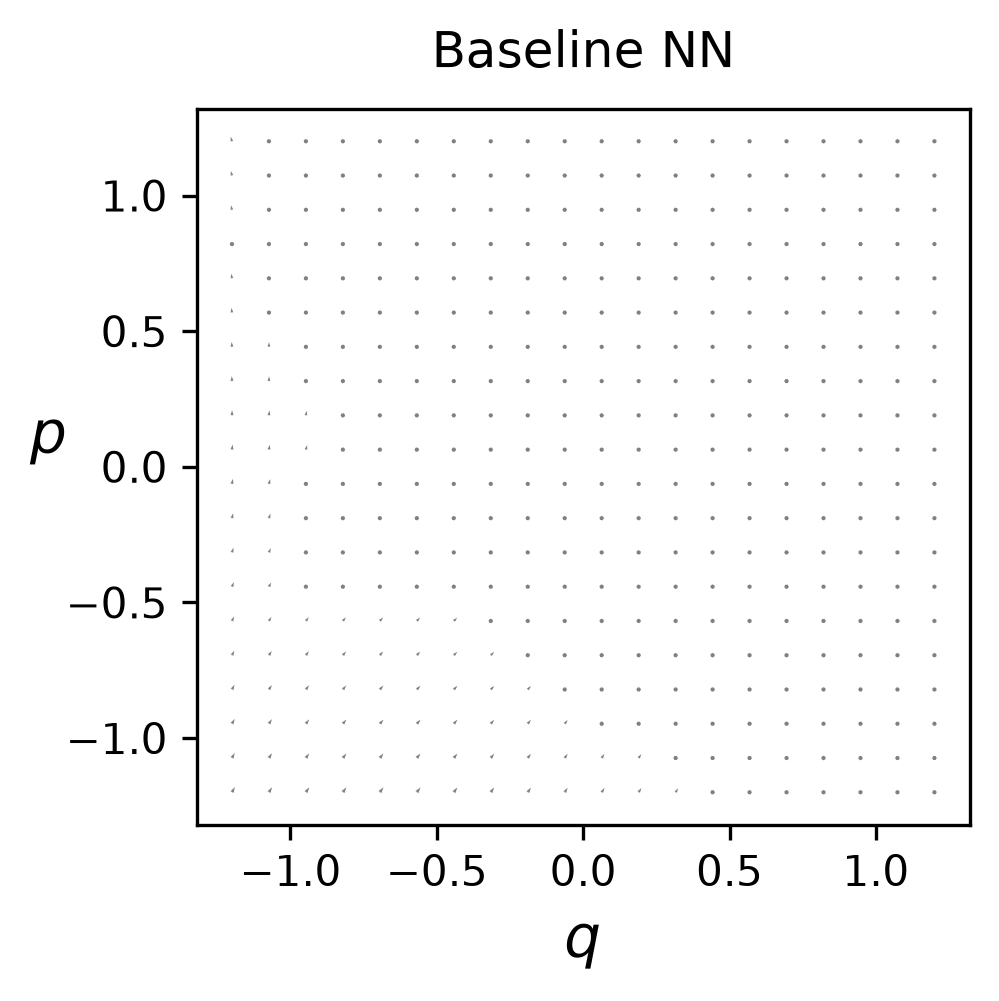

In [85]:
fig = plt.figure(figsize=(11.3, 3.1), facecolor='white', dpi=300)

fig.add_subplot(1, 3, 2, frameon=True)
plt.quiver(field['x'][:,0], field['x'][:,1], base_field[:,0], base_field[:,1],
        cmap='gray_r', scale=ARROW_SCALE, width=ARROW_WIDTH, color=(.5,.5,.5))

# for i, l in enumerate(np.split(base_ivp['y'].T, LINE_SEGMENTS)):
#     color = (float(i)/LINE_SEGMENTS, 0, 1-float(i)/LINE_SEGMENTS)
#     plt.plot(l[:,0],l[:,1],color=color, linewidth=LINE_WIDTH)
    
plt.xlabel("$q$", fontsize=14)
plt.ylabel("$p$", rotation=0, fontsize=14)
plt.title("Baseline NN", pad=10)


In [ ]:
EPOCHS = 50
CHECKPOINT_EPOCHS = {0, 1, 2, 5, 10}

field = data.get_field()
np_mesh_x = field['x']
mesh_x = torch.tensor(np_mesh_x, requires_grad=True, dtype=torch.float32).to(DEVICE)

model = BaselineMLP().to(DEVICE)

prediction_history = {}
base_ivp_history = {}
step_history = {}
total_steps = 0

criterion = nn.MSELoss()
optim = torch.optim.SGD(model.parameters(), lr=1e-03, momentum=0.9)
for e in range(EPOCHS):
    if e in CHECKPOINT_EPOCHS:
        model.eval()
        with torch.no_grad():
            prediction_history[e] = model(mesh_x).detach().cpu().numpy()
            t_span = [0,30]
            y0 = np.asarray([1., 0])
            kwargs = {'t_eval': np.linspace(t_span[0], t_span[1], 2000), 'rtol': 1e-12}
            base_ivp = integrate_model(model, t_span, y0, **kwargs)
            base_ivp_history[e] = base_ivp['y']
            step_history[e] = total_steps

    model.train()
    running_loss = 0.0

    for inputs, labels in train_dataloader:
        inputs = inputs.to(DEVICE)
        labels = labels.to(DEVICE)

        predictions = model(inputs)
        loss = criterion(predictions, labels)

        optim.zero_grad()
        loss.backward()
        optim.step()
        total_steps += 1

        running_loss += loss.item() * inputs.size(0)

    epoch_loss = running_loss / len(train_dataloader.dataset)

    if (e + 1) % 10 == 0 or e == 0:
        print(f'epoch [{e+1}/{EPOCHS} - Loss: {epoch_loss:.6f}')



epoch [1/50 - Loss: 0.714362
epoch [10/50 - Loss: 0.036237
epoch [20/50 - Loss: 0.035488
epoch [30/50 - Loss: 0.035318
epoch [40/50 - Loss: 0.035189
epoch [50/50 - Loss: 0.035038


In [103]:
history = list(prediction_history.keys())
history


[0, 1, 2, 5, 10]

In [ ]:
fig = plt.figure(figsize=(11.3, 5.1), facecolor='white', dpi=300)


fig.add_subplot(1, 5, 1, frameon=True)

pred_field = prediction_history[history[0]]
plt.quiver(field['x'][:,0], field['x'][:,1], pred_field[:,0], pred_field[:,1],
        cmap='gray_r', scale=ARROW_SCALE, width=ARROW_WIDTH, color=(.5,.5,.5))

# ivp = base_ivp_history[history[0]]
# for i, l in enumerate(np.split(ivp.T, LINE_SEGMENTS)):
#         color = (float(i)/LINE_SEGMENTS, 0, 1-float(i)/LINE_SEGMENTS)
#         plt.plot(l[:,0],l[:,1],color=color, linewidth=LINE_WIDTH)
    
plt.xlabel("$q$", fontsize=14)
plt.ylabel("$p$", rotation=0, fontsize=14)
#plt.title("Baseline NN", pad=10)
plt.title(f"steps: {step_history[history[0]]}")

###########################


fig.add_subplot(1, 5, 2, frameon=True)
pred_field = prediction_history[history[1]]
plt.quiver(field['x'][:,0], field['x'][:,1], pred_field[:,0], pred_field[:,1],
        cmap='gray_r', scale=ARROW_SCALE, width=ARROW_WIDTH, color=(.5,.5,.5))

ivp = base_ivp_history[history[1]]
for i, l in enumerate(np.split(ivp.T, LINE_SEGMENTS)):
        color = (float(i)/LINE_SEGMENTS, 0, 1-float(i)/LINE_SEGMENTS)
        plt.plot(l[:,0],l[:,1],color=color, linewidth=LINE_WIDTH)
    
plt.xlabel("$q$", fontsize=14)
plt.ylabel("$p$", rotation=0, fontsize=14)
plt.title(f"steps: {step_history[history[1]]}")
###########################


fig.add_subplot(1, 5, 3, frameon=True)
pred_field = prediction_history[history[2]]
plt.quiver(field['x'][:,0], field['x'][:,1], pred_field[:,0], pred_field[:,1],
        cmap='gray_r', scale=ARROW_SCALE, width=ARROW_WIDTH, color=(.5,.5,.5))

ivp = base_ivp_history[history[2]]
for i, l in enumerate(np.split(ivp.T, LINE_SEGMENTS)):
        color = (float(i)/LINE_SEGMENTS, 0, 1-float(i)/LINE_SEGMENTS)
        plt.plot(l[:,0],l[:,1],color=color, linewidth=LINE_WIDTH)
    
plt.xlabel("$q$", fontsize=14)
plt.ylabel("$p$", rotation=0, fontsize=14)
plt.title(f"steps: {step_history[history[2]]}")
###########################


fig.add_subplot(1, 5, 4, frameon=True)
pred_field = prediction_history[history[3]]
plt.quiver(field['x'][:,0], field['x'][:,1], pred_field[:,0], pred_field[:,1],
        cmap='gray_r', scale=ARROW_SCALE, width=ARROW_WIDTH, color=(.5,.5,.5))

ivp = base_ivp_history[history[3]]
for i, l in enumerate(np.split(ivp.T, LINE_SEGMENTS)):
        color = (float(i)/LINE_SEGMENTS, 0, 1-float(i)/LINE_SEGMENTS)
        plt.plot(l[:,0],l[:,1],color=color, linewidth=LINE_WIDTH)
    
plt.xlabel("$q$", fontsize=14)
plt.ylabel("$p$", rotation=0, fontsize=14)
plt.title(f"steps: {step_history[history[3]]}")
###########################


fig.add_subplot(1, 5, 5, frameon=True)
pred_field = prediction_history[history[4]]
plt.quiver(field['x'][:,0], field['x'][:,1], pred_field[:,0], pred_field[:,1],
        cmap='gray_r', scale=ARROW_SCALE, width=ARROW_WIDTH, color=(.5,.5,.5))

ivp = base_ivp_history[history[4]]
for i, l in enumerate(np.split(ivp.T, LINE_SEGMENTS)):
        color = (float(i)/LINE_SEGMENTS, 0, 1-float(i)/LINE_SEGMENTS)
        plt.plot(l[:,0],l[:,1],color=color, linewidth=LINE_WIDTH)
    
plt.xlabel("$q$", fontsize=14)
plt.ylabel("$p$", rotation=0, fontsize=14)
plt.title(f"steps: {step_history[history[4]]}")

NameError: name 'plt' is not defined

In [116]:
layer = nn.Linear(2, 2)
nn.init.orthogonal_(layer.weight)
print(layer.weight)

Parameter containing:
tensor([[ 0.8074, -0.5900],
        [ 0.5900,  0.8074]], requires_grad=True)


In [117]:
print(layer.weight)
print(torch.linalg.eig(layer.weight))
print(torch.abs(torch.linalg.eig(layer.weight)[0]))

Parameter containing:
tensor([[ 0.8074, -0.5900],
        [ 0.5900,  0.8074]], requires_grad=True)
torch.return_types.linalg_eig(
eigenvalues=tensor([0.8074+0.5900j, 0.8074-0.5900j], grad_fn=<LinalgEigBackward0>),
eigenvectors=tensor([[-7.0711e-01+0.0000j, -7.0711e-01-0.0000j],
        [-1.0175e-07+0.7071j, -1.0175e-07-0.7071j]],
       grad_fn=<LinalgEigBackward0>))
tensor([1., 1.], grad_fn=<AbsBackward0>)


In [121]:
a = torch.tensor([[2, 3], [4, 5]])
b = torch.tensor([[0, 1], [-1, 0]])
a @ b

tensor([[-3,  2],
        [-5,  4]])

In [125]:
def my_L2_loss(u, v):
    return (u-v).pow(2).mean()

a = torch.tensor([[3, 6], [9, 12]], dtype=torch.float32)
b = torch.tensor([[3, 5], [6, 6]], dtype=torch.float32)

loss_fn = nn.MSELoss()
print(f"mseloss: {loss_fn(a, b):6f}")

print(f"l2_loss: {my_L2_loss(a, b):.6f}")

mseloss: 11.500000
l2_loss: 11.500000


In [127]:
identity_matrix = torch.tensor([[1, 0, 0], [0, 1, 0], [0, 0, 1]], dtype=torch.int16)
some_vector = torch.tensor([6, 5, 4], dtype=torch.int16)
some_vector @ identity_matrix

tensor([6, 5, 4], dtype=torch.int16)

In [130]:
torch.eye(4).T

tensor([[1., 0., 0., 0.],
        [0., 1., 0., 0.],
        [0., 0., 1., 0.],
        [0., 0., 0., 1.]])